# Are the animals that solved it the ones the tools cannot read?

**Question.** Do species that tolerate a human insult (the tolerance atlas, Prompt 1, PR 33)
have a larger share of proteins with no function label than model organisms, and than random
species at the same distance from human?

**Decision it informs.** Whether the "nature already solved it" pitch can say that the
tolerant species are the ones current annotation cannot read (sentence 1 below), only that
non-model animals in general are hard to read (sentence 2), or neither.

**Data.** One run on Sherlock, 2026-10-20, of record: setup 48677851, download array
48677853, label array 48677854, collect 48677855 (commit ce7928d). 42 UniProt 2026_03
reference proteomes: 7 model organisms, 17 atlas species, 17 random controls (seed
20261019, matched to the atlas species in 100-million-year bins of divergence time from
human, TimeTree), and the Pacific oyster as a check on the leaderboard number. The table read
here is `run_2026-10-20/unreadable_table.tsv`, copied from the run folder.

**Measurement.** The unlabelled share is the leaderboard's (PR 12, `scripts/why/labels.py`):
the share of proteins with neither an InterPro match nor a Swiss-Prot hit above 30% identity
(a hit to its own entry counts). Swiss-Prot hits are MMseqs2 18.8cc5c easy-search
`-s 7.5 -e 1e-3 --max-seqs 1000`. InterPro matches are UniProt's cross-references to InterPro
and its member databases. A lower share is better annotated; 0% means every protein has a
label. BUSCO 6.1.0 completeness uses the kingdom dataset (metazoa_odb12, fungi_odb12,
viridiplantae_odb12).

**Rule, fixed in PLAN.md before any run (copied verbatim).** Three sentences are possible and
the figure decides which one is true:

* "The solvers are unreadable": the median unlabelled share of atlas species is at least 5 percentage points above the median of the random controls, among proteomes with BUSCO of at least 90%.
* "Non-model animals are unreadable": atlas species and random controls are within 5 points of each other, and both are at least 5 points above the model organisms. This is still a measured result about the annotation gap, and it is the honest sentence if it is what the data show; it is not the sentence about the thesis.
* "The gap is assembly quality": the difference between groups disappears when restricted to BUSCO of at least 90%, or divergence time explains it (report the correlation of unlabelled share with divergence time within each group). Report which sentence holds. Do not report the first unless the random controls were run.

In [1]:
import json
import pathlib
import sys

import matplotlib.pyplot as plt
import polars as pl
from scipy.stats import spearmanr

HERE = pathlib.Path.cwd()
REPO = HERE.parents[2]
sys.path.insert(0, str(REPO / "scripts" / "why"))
import pubfig as pf  # noqa: E402

pf.use_style()

RUN = HERE / "run_2026-10-20"
BUSCO_MIN = 90.0  # PLAN.md: "filled if BUSCO completeness is at least 90%"
GAP = 5.0  # PLAN.md: 5 percentage points
GROUPS = ["model organism", "atlas species", "random control"]
REFERENCE = "leaderboard reference"
JOBS_OF_RECORD = {"setup": 48677851, "fetch": 48677853, "label": 48677854, "collect": 48677855}

table = pl.read_csv(RUN / "unreadable_table.tsv", separator="\t")
assert table.height == 42 and table.filter(pl.col("status") != "ok").height == 0
setup_ok = dict(line.split(" ", 1) for line in (RUN / "setup_ok").read_text().splitlines())
assert setup_ok["setup_job"] == str(JOBS_OF_RECORD["setup"])
print(setup_ok["busco_version"], "| MMseqs2", setup_ok["mmseqs_version"])
print(table.group_by("group").len().sort("group"))

BUSCO 6.1.0 | MMseqs2 18.8cc5c
shape: (4, 2)
┌───────────────────────┬─────┐
│ group                 ┆ len │
│ ---                   ┆ --- │
│ str                   ┆ u32 │
╞═══════════════════════╪═════╡
│ atlas species         ┆ 17  │
│ leaderboard reference ┆ 1   │
│ model organism        ┆ 7   │
│ random control        ┆ 17  │
└───────────────────────┴─────┘


## 1. The run repeats the leaderboard numbers

The oyster and human were measured once before, in job 47961379 (leaderboard PR 12): 19.41% of
30,272 oyster proteins and 0.88% of 20,652 human proteins unlabelled, BUSCO metazoa_odb12
complete 95.68% and 100.0%. The same numbers from this run show that the per-proteome pipeline
measures the same thing.

shape: (2, 5)
┌─────────────────┬────────────┬──────────────┬────────────────┬────────────────────────┐
│ species         ┆ n_proteins ┆ n_unlabelled ┆ unlabelled_pct ┆ busco_completeness_pct │
│ ---             ┆ ---        ┆ ---          ┆ ---            ┆ ---                    │
│ str             ┆ i64        ┆ i64          ┆ f64            ┆ f64                    │
╞═════════════════╪════════════╪══════════════╪════════════════╪════════════════════════╡
│ Homo sapiens    ┆ 20652      ┆ 181          ┆ 0.88           ┆ 100.0                  │
│ Magallana gigas ┆ 30272      ┆ 5877         ┆ 19.41          ┆ 95.68                  │
└─────────────────┴────────────┴──────────────┴────────────────┴────────────────────────┘
oyster and human match the leaderboard exactly


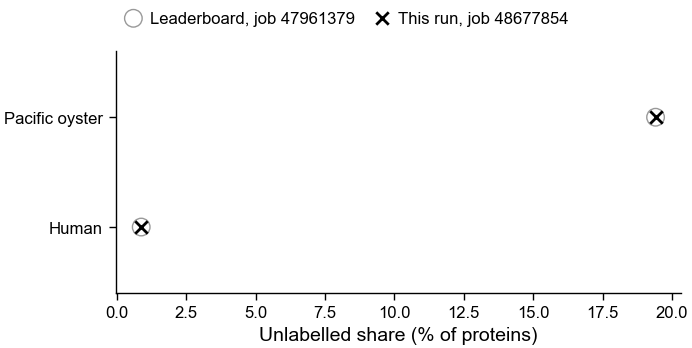

In [2]:
check = table.filter(pl.col("upid").is_in(["UP000005408", "UP000005640"])).select(
    "species", "n_proteins", "n_unlabelled", "unlabelled_pct", "busco_completeness_pct"
)
print(check)
expected = {"UP000005408": (30_272, 5_877, 19.41, 95.68), "UP000005640": (20_652, 181, 0.88, 100.0)}
for upid, (n, u, pct, busco) in expected.items():
    r = table.filter(pl.col("upid") == upid).row(0, named=True)
    assert (r["n_proteins"], r["n_unlabelled"], r["unlabelled_pct"], r["busco_completeness_pct"]) == (n, u, pct, busco), r
print("oyster and human match the leaderboard exactly")

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 45)
labels = ["Human", "Pacific oyster"]
lead = [0.88, 19.41]
this = [table.filter(pl.col("upid") == u)["unlabelled_pct"][0] for u in ("UP000005640", "UP000005408")]
ax.scatter(lead, [0, 1], marker="o", s=40, facecolor="none", edgecolor=pf.GREY, label="Leaderboard, job 47961379")
ax.scatter(this, [0, 1], marker="x", s=20, color="black", label="This run, job 48677854")
ax.set_yticks([0, 1], labels)
ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("Unlabelled share (% of proteins)")
pf.shared_legend(fig, ncol=2)
pf.save(fig, "leaderboard_check_human_oyster_uniprot_2026_03")

## 2. Group medians, all proteomes and BUSCO of at least 90%

Each group's median unlabelled share, its range and its n, first over every proteome and then
over proteomes whose BUSCO completeness (kingdom dataset) is at least 90%. The oyster is a
check on the method and is in no group.

All proteomes
shape: (3, 5)
┌────────────────┬─────┬────────────┬─────────┬─────────┐
│ group          ┆ n   ┆ median_pct ┆ min_pct ┆ max_pct │
│ ---            ┆ --- ┆ ---        ┆ ---     ┆ ---     │
│ str            ┆ u32 ┆ f64        ┆ f64     ┆ f64     │
╞════════════════╪═════╪════════════╪═════════╪═════════╡
│ model organism ┆ 7   ┆ 2.57       ┆ 0.02    ┆ 19.16   │
│ atlas species  ┆ 17  ┆ 2.02       ┆ 0.31    ┆ 40.52   │
│ random control ┆ 17  ┆ 6.63       ┆ 0.02    ┆ 40.75   │
└────────────────┴─────┴────────────┴─────────┴─────────┘
BUSCO >= 90%
shape: (3, 5)
┌────────────────┬─────┬────────────┬─────────┬─────────┐
│ group          ┆ n   ┆ median_pct ┆ min_pct ┆ max_pct │
│ ---            ┆ --- ┆ ---        ┆ ---     ┆ ---     │
│ str            ┆ u32 ┆ f64        ┆ f64     ┆ f64     │
╞════════════════╪═════╪════════════╪═════════╪═════════╡
│ model organism ┆ 5   ┆ 2.57       ┆ 0.88    ┆ 13.25   │
│ atlas species  ┆ 8   ┆ 1.66       ┆ 0.31    ┆ 23.24   │
│ random control 

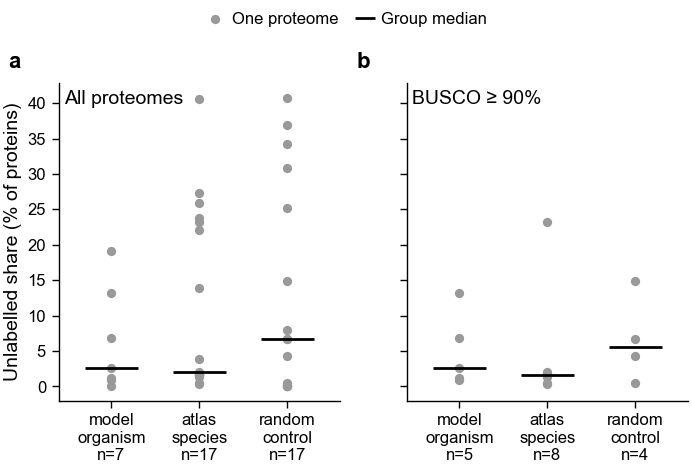

In [3]:
groups = table.filter(pl.col("group") != REFERENCE)
good = groups.filter(pl.col("busco_completeness_pct") >= BUSCO_MIN)


def medians(df):
    return (
        df.group_by("group")
        .agg(
            n=pl.len(),
            median_pct=pl.col("unlabelled_pct").median(),
            min_pct=pl.col("unlabelled_pct").min(),
            max_pct=pl.col("unlabelled_pct").max(),
        )
        .sort(pl.col("group").replace_strict({g: i for i, g in enumerate(GROUPS)}))
    )


med_all, med_good = medians(groups), medians(good)
print("All proteomes"); print(med_all)
print(f"BUSCO >= {BUSCO_MIN:.0f}%"); print(med_good)
m_all = dict(zip(med_all["group"], med_all["median_pct"]))
m_good = dict(zip(med_good["group"], med_good["median_pct"]))

fig, axs = pf.figure(pf.ONE_COLUMN_MM, 60, ncols=2, sharey=True)
for ax, df, title in zip(axs, (groups, good), ("All proteomes", f"BUSCO ≥ {BUSCO_MIN:.0f}%")):
    for i, g in enumerate(GROUPS):
        v = df.filter(pl.col("group") == g)["unlabelled_pct"].to_list()
        ax.scatter([i] * len(v), v, s=8, color=pf.GREY, label="One proteome" if i == 0 else None)
        ax.hlines(medians(df).filter(pl.col("group") == g)["median_pct"][0], i - 0.3, i + 0.3, color="black", label="Group median" if i == 0 else None)
    ax.set_xticks(range(3), [f"{g.split()[0]}\n{g.split()[1]}\nn={df.filter(pl.col('group') == g).height}" for g in GROUPS])
    ax.set_xlim(-0.6, 2.6)
    ax.text(0.02, 0.98, title, transform=ax.transAxes, va="top")
axs[0].set_ylabel("Unlabelled share (% of proteins)")
pf.shared_legend(fig, ncol=2)
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, "group_medians_unlabelled_share_uniprot_2026_03")

## 3. Divergence time within each group

Spearman's rank correlation (rho: +1 when the share always rises with divergence time, 0 when
it does not follow it) of unlabelled share with TimeTree divergence time from human, within
each group, over every proteome.

In [4]:
spearman = {}
rows = []
for g in GROUPS:
    s = groups.filter(pl.col("group") == g)
    r = spearmanr(s["divergence_my"], s["unlabelled_pct"])
    spearman[g] = {"n": s.height, "rho": round(float(r.statistic), 3), "p": round(float(r.pvalue), 4)}
    rows.append({"group": g, **spearman[g]})
print(pl.DataFrame(rows))

shape: (3, 4)
┌────────────────┬─────┬───────┬────────┐
│ group          ┆ n   ┆ rho   ┆ p      │
│ ---            ┆ --- ┆ ---   ┆ ---    │
│ str            ┆ i64 ┆ f64   ┆ f64    │
╞════════════════╪═════╪═══════╪════════╡
│ model organism ┆ 7   ┆ 0.27  ┆ 0.5577 │
│ atlas species  ┆ 17  ┆ 0.82  ┆ 0.0001 │
│ random control ┆ 17  ┆ 0.592 ┆ 0.0123 │
└────────────────┴─────┴───────┴────────┘


## 4. The figure the rule asks for

x: divergence time from human (million years, TimeTree). y: unlabelled share (% of proteins).
One mark per proteome; shape and colour say the group; filled means BUSCO completeness of at
least 90% (kingdom dataset), hollow means less. Proteomes at the same TimeTree age are moved
sideways (by group, then a few million years apart within a group) so none hides another;
their true age is the one TimeTree gives for the whole lineage, listed in the table below. The oyster (a check, in no group) and human are labelled.

shape: (42, 5)
┌────────────────┬────────────────────────┬───────────────┬────────────────┬───────────────────────┐
│ group          ┆ species                ┆ divergence_my ┆ unlabelled_pct ┆ busco_completeness_pc │
│ ---            ┆ ---                    ┆ ---           ┆ ---            ┆ t                     │
│ str            ┆ str                    ┆ f64           ┆ f64            ┆ ---                   │
│                ┆                        ┆               ┆                ┆ f64                   │
╞════════════════╪════════════════════════╪═══════════════╪════════════════╪═══════════════════════╡
│ atlas species  ┆ Heterocephalus glaber  ┆ 83.51396      ┆ 1.79           ┆ 98.21                 │
│ atlas species  ┆ Urocitellus parryii    ┆ 83.51396      ┆ 1.32           ┆ 95.98                 │
│ atlas species  ┆ Ictidomys              ┆ 83.51396      ┆ 0.31           ┆ 93.9                  │
│                ┆ tridecemlineatus       ┆               ┆                ┆

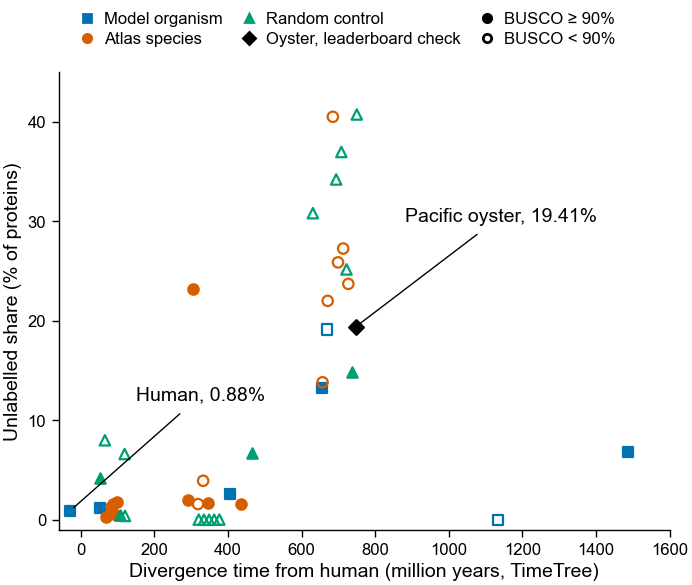

In [5]:
STYLE = {
    "model organism": dict(marker="s", color=pf.OKABE_ITO["blue"]),
    "atlas species": dict(marker="o", color=pf.OKABE_ITO["vermillion"]),
    "random control": dict(marker="^", color=pf.OKABE_ITO["bluish_green"]),
    REFERENCE: dict(marker="D", color="black"),
}
DODGE_MY = {"model organism": -30, "atlas species": 0, "random control": 30, REFERENCE: 55}

fig, ax = pf.figure(pf.ONE_COLUMN_MM, 75)
SPREAD_MY = 14  # proteomes of one group at one TimeTree age sit this far apart, so none is hidden
plot_rows = (
    table.sort("upid")
    .with_columns(
        k=pl.col("upid").cum_count().over("group", "divergence_my") - 1,
        n_same=pl.len().over("group", "divergence_my"),
    )
    .with_columns(
        x=pl.col("divergence_my")
        + pl.col("group").replace_strict(DODGE_MY, return_dtype=pl.Float64)
        + (pl.col("k") - (pl.col("n_same") - 1) / 2) * SPREAD_MY
    )
)
for g, st in STYLE.items():
    for filled in (True, False):
        s = plot_rows.filter((pl.col("group") == g) & ((pl.col("busco_completeness_pct") >= BUSCO_MIN) == filled))
        if s.height:
            ax.scatter(s["x"], s["unlabelled_pct"], s=14, marker=st["marker"], edgecolor=st["color"],
                       facecolor=st["color"] if filled else "none", linewidth=0.8, zorder=3)
labels = {"UP000005640": ("Human, 0.88%", (150, 12)), "UP000005408": ("Pacific oyster, 19.41%", (880, 30))}
for upid, (text, xy_text) in labels.items():
    r = plot_rows.filter(pl.col("upid") == upid).row(0, named=True)
    ax.annotate(text, (r["x"], r["unlabelled_pct"]), xytext=xy_text, textcoords="data",
                arrowprops=dict(arrowstyle="-", lw=0.5, color="black"))
ax.set_xlabel("Divergence time from human (million years, TimeTree)")
ax.set_ylabel("Unlabelled share (% of proteins)")
ax.set_xlim(-60, 1600)
ax.set_ylim(-1, 45)

from matplotlib.lines import Line2D  # noqa: E402

handles = [Line2D([], [], linestyle="none", marker=st["marker"], markeredgecolor=st["color"], markerfacecolor=st["color"],
                  label={"model organism": "Model organism", "atlas species": "Atlas species", "random control": "Random control",
                         REFERENCE: "Oyster, leaderboard check"}[g]) for g, st in STYLE.items()]
handles += [Line2D([], [], linestyle="none", marker="o", markeredgecolor="black", markerfacecolor="black", label="BUSCO ≥ 90%"),
            Line2D([], [], linestyle="none", marker="o", markeredgecolor="black", markerfacecolor="none", label="BUSCO < 90%")]
fig.legend(handles=handles, loc="outside upper center", ncol=3)
with pl.Config(tbl_rows=50):
    print(plot_rows.select("group", "species", "divergence_my", "unlabelled_pct", "busco_completeness_pct").sort("group", "divergence_my"))
print("marks drawn:", plot_rows.height)
pf.save(fig, "unlabelled_share_vs_divergence_time_uniprot_2026_03")

## 5. The rule, applied

In [6]:
def gap(a, b, m):
    return round(m[a] - m[b], 2)


atlas_minus_control_good = gap("atlas species", "random control", m_good)
s1 = atlas_minus_control_good >= GAP

s2 = {}
for name, m in (("all", m_all), ("busco_90", m_good)):
    within = abs(gap("atlas species", "random control", m)) < GAP
    above = gap("atlas species", "model organism", m) >= GAP and gap("random control", "model organism", m) >= GAP
    s2[name] = {"atlas_minus_control": gap("atlas species", "random control", m),
                "atlas_minus_model": gap("atlas species", "model organism", m),
                "control_minus_model": gap("random control", "model organism", m),
                "within_5": within, "both_5_above_models": above, "holds": within and above}

# Sentence 3: a group difference that is there over all proteomes and goes away at BUSCO >= 90%,
# or divergence time explaining it. Atlas and controls were matched on divergence time by design.
diffs_all = {k: s2["all"][k] for k in ("atlas_minus_control", "atlas_minus_model", "control_minus_model")}
diffs_good = {k: s2["busco_90"][k] for k in ("atlas_minus_control", "atlas_minus_model", "control_minus_model")}
any_gap_all = any(abs(v) >= GAP for v in diffs_all.values())
print("Sentence 1, atlas minus controls among BUSCO >= 90%:", atlas_minus_control_good, "points; holds:", s1)
print("Sentence 2:", json.dumps(s2, indent=1))
print("Group differences, all proteomes:", diffs_all)
print("Group differences, BUSCO >= 90%:", diffs_good)
print("Any group difference of 5 points or more over all proteomes:", any_gap_all)
print("Spearman within groups:", spearman)

Sentence 1, atlas minus controls among BUSCO >= 90%: -3.84 points; holds: False
Sentence 2: {
 "all": {
  "atlas_minus_control": -4.61,
  "atlas_minus_model": -0.55,
  "control_minus_model": 4.06,
  "within_5": true,
  "both_5_above_models": false,
  "holds": false
 },
 "busco_90": {
  "atlas_minus_control": -3.84,
  "atlas_minus_model": -0.91,
  "control_minus_model": 2.94,
  "within_5": true,
  "both_5_above_models": false,
  "holds": false
 }
}
Group differences, all proteomes: {'atlas_minus_control': -4.61, 'atlas_minus_model': -0.55, 'control_minus_model': 4.06}
Group differences, BUSCO >= 90%: {'atlas_minus_control': -3.84, 'atlas_minus_model': -0.91, 'control_minus_model': 2.94}
Any group difference of 5 points or more over all proteomes: False
Spearman within groups: {'model organism': {'n': 7, 'rho': 0.27, 'p': 0.5577}, 'atlas species': {'n': 17, 'rho': 0.82, 'p': 0.0001}, 'random control': {'n': 17, 'rho': 0.592, 'p': 0.0123}}


In [7]:
cpu_rows = []
for line in (RUN / "sacct.txt").read_text().splitlines()[1:]:
    f = line.split("|")
    if "." not in f[0]:
        cpu_rows.append({"job": f[0], "elapsed": f[3], "total_cpu": f[4], "cpus": int(f[7])})


def hours(t):
    days = 0
    if "-" in t:
        d, t = t.split("-", 1)
        days = int(d)
    parts = [float(x) for x in t.split(":")]
    while len(parts) < 3:
        parts.insert(0, 0.0)
    return days * 24 + parts[0] + parts[1] / 60 + parts[2] / 3600


cpu = pl.DataFrame(cpu_rows).with_columns(
    cpu_h=pl.col("total_cpu").map_elements(hours, return_dtype=pl.Float64),
    reserved_core_h=pl.col("elapsed").map_elements(hours, return_dtype=pl.Float64) * pl.col("cpus"),
    step=pl.col("job").str.split("_").list.first().cast(pl.Int64).replace_strict({v: k for k, v in JOBS_OF_RECORD.items()}, default="other"),
)
by_step = cpu.group_by("step").agg(jobs=pl.len(), cpu_h=pl.col("cpu_h").sum(), reserved_core_h=pl.col("reserved_core_h").sum()).sort("step")
print(by_step)
total_cpu_h = round(cpu["cpu_h"].sum(), 2)
print("CPU-hours, whole run:", total_cpu_h, "| reserved core-hours:", round(cpu["reserved_core_h"].sum(), 2))

verdict = {
    "question": "Do tolerant species (atlas) have a larger unlabelled share than model organisms and matched random controls?",
    "definition": "share of proteins with neither an InterPro match nor a Swiss-Prot hit above 30% identity (a hit to its own entry counts)",
    "uniprot_release": "2026_03",
    "jobs_of_record": JOBS_OF_RECORD,
    "busco_min_pct": BUSCO_MIN,
    "gap_points": GAP,
    "medians_all": m_all,
    "medians_busco_90": m_good,
    "n_all": dict(zip(med_all["group"], med_all["n"])),
    "n_busco_90": dict(zip(med_good["group"], med_good["n"])),
    "sentence_held": "none" if not (s1 or s2["all"]["holds"] or s2["busco_90"]["holds"] or any_gap_all) else "check",
    "sentence_1_solvers_unreadable": {"atlas_minus_control_busco_90": atlas_minus_control_good, "holds": s1},
    "sentence_2_non_model_unreadable": s2,
    "sentence_3_assembly_quality": {
        "group_differences_all": diffs_all,
        "group_differences_busco_90": diffs_good,
        "any_difference_of_5_points_all": any_gap_all,
        "spearman_divergence_within_group": spearman,
    },
    "oyster_repeats_leaderboard": {"unlabelled_pct": 19.41, "n_unlabelled": 5_877, "n_proteins": 30_272, "matches": True},
    "cpu_hours_total": total_cpu_h,
    "cpu_hours_by_step": {r["step"]: round(r["cpu_h"], 3) for r in by_step.iter_rows(named=True)},
    "proteomes": [
        {k: r[k] for k in ("group", "species", "upid", "proteome_taxid", "divergence_my", "n_proteins", "n_unlabelled",
                           "unlabelled_pct", "n_uncharacterized_name", "uncharacterized_name_pct", "busco_lineage",
                           "busco_completeness_pct", "busco_lineage_all", "busco_all_completeness_pct", "label_cpu_h",
                           "label_wall_h", "label_maxrss_gib", "fetch_cpu_h")}
        for r in table.iter_rows(named=True)
    ],
}
(HERE / "verdict.json").write_text(json.dumps(verdict, indent=1) + "\n")
print("wrote verdict.json:", len(verdict["proteomes"]), "proteomes")

shape: (3, 4)
┌───────┬──────┬───────────┬─────────────────┐
│ step  ┆ jobs ┆ cpu_h     ┆ reserved_core_h │
│ ---   ┆ ---  ┆ ---       ┆ ---             │
│ str   ┆ u32  ┆ f64       ┆ f64             │
╞═══════╪══════╪═══════════╪═════════════════╡
│ fetch ┆ 42   ┆ 0.016266  ┆ 1.528333        │
│ label ┆ 42   ┆ 38.140863 ┆ 50.933333       │
│ setup ┆ 1    ┆ 0.025514  ┆ 0.645556        │
└───────┴──────┴───────────┴─────────────────┘
CPU-hours, whole run: 38.18 | reserved core-hours: 53.11
wrote verdict.json: 42 proteomes


## Summary and conclusions

**Verdict: none of the three sentences holds as the rule is written.** The atlas species are
not less readable than matched random species; if anything they are more readable.

- Among proteomes with BUSCO of at least 90%, the median unlabelled share is 1.66% for the 8
  atlas species and 5.505% for the 4 random controls: atlas minus controls is -3.84 points,
  not +5 or more. Sentence 1 ("the solvers are unreadable") does not hold.
- Over all proteomes the medians are 2.57% for the 7 model organisms, 2.02% for the 17 atlas
  species and 6.63% for the 17 controls. Atlas and controls are within 5 points (4.61 apart),
  but the atlas median is 0.55 points below the model organisms and the controls only 4.06
  above them, so sentence 2 ("non-model animals are unreadable") does not hold. With BUSCO of
  at least 90% the same: 0.91 below and 2.94 above.
- Sentence 3 does not hold either: no group difference reaches 5 points even before the BUSCO
  cut, so there is no gap for assembly quality to remove. The atlas-minus-controls difference
  shrinks only from -4.61 to -3.84 points at BUSCO of at least 90%. Divergence time is
  matched between atlas and controls by design, so it cannot explain that difference.
- Within a group, the share rises with divergence time from human: Spearman rho 0.82 for the
  atlas species (n = 17, p = 0.0001), 0.59 for the controls (n = 17, p = 0.012) and 0.27 for
  the model organisms (n = 7, p = 0.56). The proteomes with the most unlabelled proteins
  (13% to 41%) are the invertebrates at 692 million years (the tardigrade, the clam, the
  insects, the worms), and most of them have BUSCO below 90%.
- The run repeats the leaderboard: oyster 19.41% (5,877 of 30,272) and human 0.88% (181 of
  20,652), BUSCO 95.68% and 100.0%.

**What this means for the pitch.** The data do not support "the animals that solved it are the
ones the tools cannot read". The unlabelled share follows distance from human, and within the
invertebrates it is highest where BUSCO is low, rather than following tolerance. Matching by
bin gave both groups 11 vertebrates and 6 invertebrates, so the gap between them comes from
which species were drawn: the five birds drawn in the 300 to 400 million year bin have almost
no unlabelled proteins (0.02% to 0.04%), and the five mammals drawn near human include two
monkeys at 4.26% and 8.01%. With 8 atlas species and 4 controls above 90% BUSCO, the test is
small.

**Not done here.** The second agent's recompute of every share from the raw annotation
tables, of the medians from `verdict.json`, and of the control draw from its seed
(`VERIFY_TODO.md`).